# DSA4212 Group 1 · Report figures

This notebook reproduces Figures 1–4 of *Discovery and Refinement in
Multimodal Black-Box Optimisation*. Figure 1 is analytical. Figures 2–4
use the original per-run logs from the [project repository](https://github.com/bbny27/DSA4212-G1/tree/e2863a9c4a7d237938771be24634e8711d109616).

**Run in Jupyter.** Install the plotting dependencies in the notebook's
Python environment, then restart the kernel and run all cells.

```python
%pip install "numpy>=1.24" "scipy>=1.10" "matplotlib>=3.7"
```

The LaTeX archive bundles the input logs in `figure_data/`. If you opened
the notebook by itself, the data loader downloads missing logs from the
pinned GitHub commit. It verifies the SHA-256 checksum of each input.

All four figures appear below and are saved as vector PDFs in `figures/`.
To update the report, run this notebook beside `main.tex` and recompile
LaTeX. The notebook reproduces plots from recorded runs. Running the
optimisers again is a separate workflow in the repository.

## Setup

In [1]:
from hashlib import sha256
import json
from pathlib import Path
from urllib.error import URLError
from urllib.request import urlopen

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from matplotlib.ticker import PercentFormatter
import numpy as np
from scipy.stats import binomtest

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "figure_data"
FIGURE_DIR = PROJECT_DIR / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

BUDGET = 50
INITIAL_EVALUATIONS = 12
DISCOVERY_TARGET = 1.0
PRECISION_TARGET = 1e-2

NAVY, ORANGE, TEAL, GREY = "#174B72", "#AE471D", "#167766", "#5C6470"
mpl.rcParams.update({
    "font.family": "DejaVu Serif",
    "font.size": 10,
    "mathtext.fontset": "dejavuserif",
    "pdf.fonttype": 42,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.labelsize": 8.9,
    "axes.titlesize": 8.9,
    "axes.titleweight": "normal",
    "axes.axisbelow": True,
    "legend.fontsize": 8.9,
    "xtick.labelsize": 8.9,
    "ytick.labelsize": 8.9,
    "grid.color": "#DDE2E6",
    "grid.linewidth": 0.55,
    "figure.dpi": 145,
})


def export_figure(fig, filename):
    fig.savefig(FIGURE_DIR / filename, bbox_inches="tight", pad_inches=0.035)
    plt.show()
    plt.close(fig)

## Figure 1 · Benchmark geometry

The left panel evaluates the objective at $x_2=0$. The right panel
compares the disks $\{x:f_c(x)<1\}$ for $c=0$ and $c=30$ with
the fixed core and the precision disk. No run data are needed.

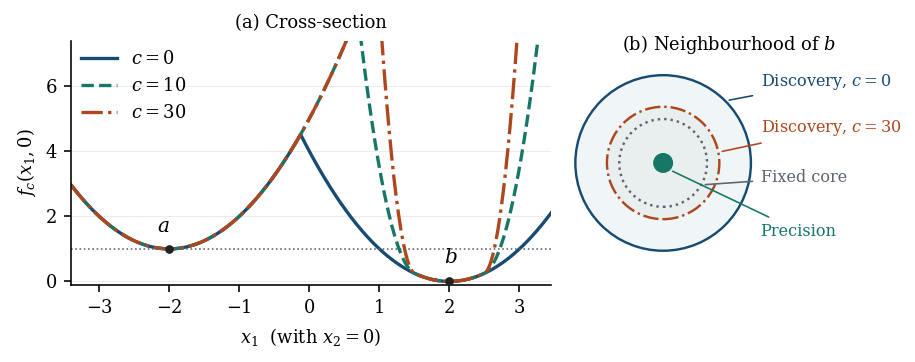

In [2]:
A = np.array([-2.0, 0.0])
B = np.array([2.0, 0.0])
CORE_RADIUS = 0.5


def objective(x, c):
    x = np.asarray(x)
    distance_a = np.linalg.norm(x - A, axis=-1)
    distance_b = np.linalg.norm(x - B, axis=-1)
    branch_a = 1 + distance_a**2
    branch_b = distance_b**2 + c * np.maximum(distance_b - CORE_RADIUS, 0)**2
    return np.minimum(branch_a, branch_b)


def discovery_radius(c):
    r0 = CORE_RADIUS
    return (c*r0 + np.sqrt(1 + c*(1-r0**2))) / (1+c)


fig, (cross, disks) = plt.subplots(
    1, 2, figsize=(6.2, 2.38), width_ratios=[1.45, 1], layout="constrained"
)

x1 = np.linspace(-3.4, 3.45, 900)
section = np.column_stack((x1, np.zeros_like(x1)))
for c, colour, linestyle in [(0, NAVY, "-"), (10, TEAL, "--"), (30, ORANGE, "-.")]:
    cross.plot(x1, objective(section, c), color=colour, ls=linestyle,
               lw=1.65, label=fr"$c={c}$")
cross.axhline(DISCOVERY_TARGET, color=GREY, lw=0.8, ls=":")
cross.set(
    xlim=(-3.4, 3.45), ylim=(-0.12, 7.4), xlabel=r"$x_1$  (with $x_2=0$)",
    ylabel=r"$f_c(x_1,0)$", title="(a) Cross-section"
)
cross.scatter([A[0], B[0]], [1, 0], c="#222222", s=11, zorder=4)
cross.annotate(r"$a$", A + [0, 1], (-2.18, 1.53))
cross.annotate(r"$b$", B, (1.92, 0.58))
cross.legend(frameon=False, loc="upper left", borderaxespad=0.15, handlelength=2)
cross.grid(axis="y", alpha=0.6)

regions = [
    (discovery_radius(0), "#F0F5F8", NAVY, "-", r"Discovery, $c=0$", 45, 0.88),
    (discovery_radius(30), "#E9EEEF", ORANGE, "-.", r"Discovery, $c=30$", 11, 0.35),
    (CORE_RADIUS, "none", GREY, ":", "Fixed core", -30, -0.22),
    (np.sqrt(PRECISION_TARGET), TEAL, TEAL, "-", "Precision", -48, -0.83),
]
for radius, fill, colour, linestyle, label, angle, text_height in regions:
    disks.add_patch(Circle(B, radius, fc=fill, ec=colour, ls=linestyle, lw=1.2))
    theta = np.deg2rad(angle)
    xy = B + radius * np.array([np.cos(theta), np.sin(theta)])
    disks.annotate(label, xy, (3.11, text_height), fontsize=8, color=colour,
                   arrowprops={"arrowstyle": "-", "color": colour, "lw": 0.8})
disks.set(xlim=(0.86, 4.63), ylim=(-1.15, 1.15), title=r"(b) Neighbourhood of $b$")
disks.set_aspect("equal")
disks.axis("off")
export_figure(fig, "problem_geometry.pdf")

## Load and validate the run logs

Use the bundled copy when available. If an input is absent, retrieve it
from the pinned repository and check that its contents match the report's
input. The helper for hitting times uses strict inequalities and retains
unsuccessful runs in the denominator.

In [3]:
COMMIT = "e2863a9c4a7d237938771be24634e8711d109616"
REPOSITORY_RAW = f"https://raw.githubusercontent.com/bbny27/DSA4212-G1/{COMMIT}/"
LOGS = {
    "baseline_runs.json": (
        "code/results/experiment_1/20261107T080438768362Z/results.json",
        "dd9239990c9d478fee3770412208926dcc3a8c3c6ee588da33c91b1b142cefc8",
    ),
    "bo_continuations.jsonl": (
        "code/results/experiment_2a_bo/20261107T083253056685Z/runs.jsonl",
        "658482e7a4fd2948b2a496f857a5eed3c35ae57d76e3f93370e1b0ca3b164adf",
    ),
    "controlled_runs.jsonl": (
        "code/results/experiment_3/20261109T072157885642Z/runs.jsonl",
        "7df72581f790987a8987d6cd22bbe8426942bd134db6136116902f3ae33a73d0",
    ),
}


def log_bytes(filename):
    repository_path, expected_hash = LOGS[filename]
    bundled = DATA_DIR / filename
    if bundled.is_file():
        data = bundled.read_bytes()
    else:
        try:
            with urlopen(REPOSITORY_RAW + repository_path, timeout=45) as response:
                data = response.read()
        except (URLError, TimeoutError) as exc:
            raise RuntimeError(
                f"Could not retrieve {filename}. Extract the LaTeX archive and "
                "run the notebook with its figure_data folder in the working directory."
            ) from exc

    if sha256(data).hexdigest() != expected_hash:
        raise ValueError(f"{filename} differs from the pinned input used in the report.")
    if not bundled.is_file():
        DATA_DIR.mkdir(exist_ok=True)
        bundled.write_bytes(data)
    return data


def read_jsonl(filename):
    return [json.loads(line) for line in log_bytes(filename).splitlines() if line]


def index_trajectories(records, condition_key, method_key):
    # Map each (condition, method) to its seed-indexed objective histories.
    grouped = {}
    for record in records:
        key = (record[condition_key], record[method_key])
        group = grouped.setdefault(key, {})
        seed = record["seed"]
        values = np.asarray(record["y"], dtype=float)
        if seed in group or values.shape != (BUDGET,) or not np.isfinite(values).all():
            raise ValueError(f"Invalid or duplicate trajectory: {key}, seed={seed}")
        group[seed] = values
    return grouped


def first_hitting_time(values, target):
    hits = np.flatnonzero(values < target)
    return int(hits[0]) + 1 if hits.size else np.inf


def attainment_curve(seed_to_values, target, total_evaluations):
    times = np.array([first_hitting_time(y, target) for y in seed_to_values.values()])
    return (times[:, None] <= total_evaluations[None, :]).mean(axis=0)


def format_attainment_panel(ax, budget):
    ax.set(xlim=(0, budget), ylim=(-0.015, 1.02), yticks=np.linspace(0, 1, 6))
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    ax.grid(axis="y")


def finish_attainment_figure(fig, axes, xlabel, filename):
    for ax in axes:
        ax.set_xlabel(xlabel, labelpad=4)
    axes[0].set_ylabel("Proportion of runs")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False,
               columnspacing=1.3, handlelength=2.25, bbox_to_anchor=(0.5, 1.025))
    fig.subplots_adjust(top=0.78, bottom=0.2, left=0.095, right=0.992, wspace=0.11)
    export_figure(fig, filename)

## Figure 2 · Baseline discovery attainment

At evaluation $t$, the ordinate is the fraction of the ten runs for
which $\min_{1\le i\le t}f_c(x_i)<1$. The plot shows the two penalties
used in the continuation study.

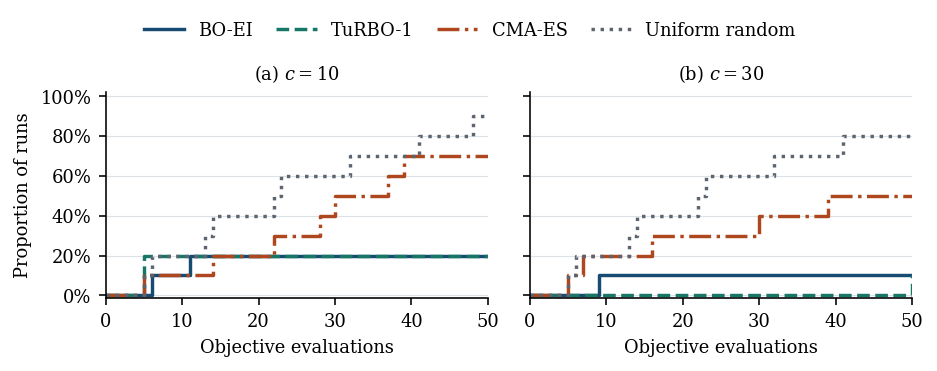

In [4]:
baseline_records = json.loads(log_bytes("baseline_runs.json"))["runs"]
baseline = index_trajectories(baseline_records, "c", "method")
baseline_styles = [
    ("BO", "BO-EI", NAVY, "-"),
    ("TuRBO-1", "TuRBO-1", TEAL, "--"),
    ("CMA-ES", "CMA-ES", ORANGE, "-."),
    ("Random", "Uniform random", GREY, ":"),
]
evaluation_counts = np.arange(BUDGET + 1)

fig, axes = plt.subplots(1, 2, figsize=(6.2, 2.45), sharey=True)
for panel, (ax, c) in enumerate(zip(axes, (10, 30))):
    for method, label, colour, linestyle in baseline_styles:
        runs = baseline[c, method]
        assert len(runs) == 10
        fraction = attainment_curve(runs, DISCOVERY_TARGET, evaluation_counts)
        ax.step(evaluation_counts, fraction, where="post", color=colour,
                ls=linestyle, lw=1.7, label=label)
    format_attainment_panel(ax, BUDGET)
    ax.set_title(fr"({chr(97 + panel)}) $c={c}$")

finish_attainment_figure(fig, axes, "Objective evaluations", "baseline_hits.pdf")

## Figure 3 · Paired differences in BO-EI target attainment

For each penalty, the variants share their first 12 observations within
a seed. We compare the binary target outcomes at evaluation 50. Let
$n_+$ and $n_-$ denote the numbers of intervention-only and
comparator-only successes. The paired estimate is $(n_+-n_-)/n$.

For a 95% interval on this difference, compute a two-sided 97.5%
Clopper–Pearson interval $[L_+,U_+]$ for the first discordant
proportion and $[L_-,U_-]$ for the second. Bonferroni's inequality
gives the conservative interval $[L_+-U_-,U_+-L_-]$ for each
contrast. The plot uses percentage points.

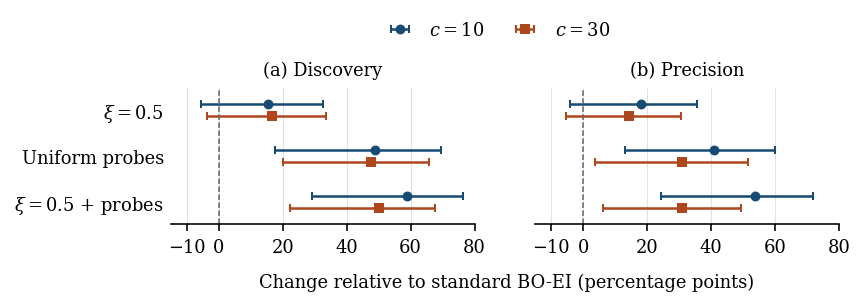

In [5]:
def paired_risk_difference(comparator, intervention, target):
    if comparator.keys() != intervention.keys():
        raise ValueError("The comparator and intervention must use the same seeds.")
    differences = []
    for seed in sorted(comparator):
        control_hit = np.any(comparator[seed] < target)
        intervention_hit = np.any(intervention[seed] < target)
        differences.append(int(intervention_hit) - int(control_hit))
    differences = np.asarray(differences)
    n = len(differences)
    n_plus = np.count_nonzero(differences == 1)
    n_minus = np.count_nonzero(differences == -1)

    plus = binomtest(n_plus, n).proportion_ci(confidence_level=0.975, method="exact")
    minus = binomtest(n_minus, n).proportion_ci(confidence_level=0.975, method="exact")
    return 100 * np.array([
        (n_plus - n_minus) / n,
        plus.low - minus.high,
        plus.high - minus.low,
    ])


continuations = index_trajectories(read_jsonl("bo_continuations.jsonl"), "c", "arm")
interventions = [
    ("Higher xi", r"$\xi=0.5$"),
    ("Uniform probes", "Uniform probes"),
    ("Higher xi + probes", r"$\xi=0.5$ + probes"),
]
penalties = [(10, 0.125, NAVY, "o", 39), (30, -0.125, ORANGE, "s", 42)]
targets = [(DISCOVERY_TARGET, "Discovery"), (PRECISION_TARGET, "Precision")]

fig, axes = plt.subplots(1, 2, figsize=(6.25, 1.94), sharey=True)
for panel, (ax, (target, title)) in enumerate(zip(axes, targets)):
    for index, (method, _) in enumerate(interventions):
        for c, offset, colour, marker, expected_n in penalties:
            comparator = continuations[c, "Ordinary EI"]
            intervention = continuations[c, method]
            assert len(comparator) == len(intervention) == expected_n
            for seed, values in comparator.items():
                prefix = values[:INITIAL_EVALUATIONS]
                assert prefix.min() >= DISCOVERY_TARGET
                assert np.array_equal(prefix, intervention[seed][:INITIAL_EVALUATIONS])

            estimate, lower, upper = paired_risk_difference(comparator, intervention, target)
            ax.errorbar(
                estimate, len(interventions) - index - 1 + offset,
                xerr=[[estimate-lower], [upper-estimate]], fmt=marker, markersize=3.9,
                color=colour, lw=1.25, capsize=2, label=fr"$c={c}$" if index == 0 else None,
            )

    ax.axvline(0, color=GREY, ls="--", lw=0.75)
    ax.set(xlim=(-15, 80), ylim=(-0.48, 2.48), xticks=[-10, 0, 20, 40, 60, 80],
           yticks=[2, 1, 0], yticklabels=[label for _, label in interventions],
           title=f"({chr(97 + panel)}) {title}")
    ax.tick_params(axis="y", length=0)
    ax.spines["left"].set_visible(False)
    ax.grid(axis="x")

fig.subplots_adjust(top=0.72, bottom=0.235, left=0.24, right=0.977, wspace=0.2)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.60, 1.015),
           ncol=2, frameon=False, columnspacing=1.4, handlelength=1.7)
fig.text(0.61, 0.01, "Change relative to standard BO-EI (percentage points)",
         ha="center", fontsize=mpl.rcParams["axes.labelsize"])
export_figure(fig, "bo_paired_effects.pdf")

## Figure 4 · Target attainment under controlled initial designs

The horizontal axis starts immediately after the 12-evaluation initial
design. From near A, plot discovery ($F_t<1$). From near B, plot
precision attainment ($F_t<10^{-2}$). The denominator is 50 per
method and initial design.

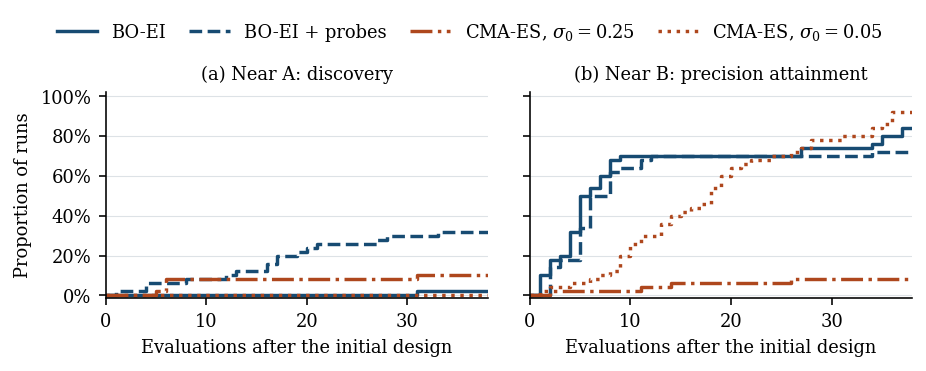

In [6]:
controlled = index_trajectories(read_jsonl("controlled_runs.jsonl"), "state", "arm")
controlled_styles = [
    ("Ordinary BO-EI", "BO-EI", NAVY, "-"),
    ("BO-EI + uniform probes", "BO-EI + probes", NAVY, "--"),
    ("CMA-ES default scale", r"CMA-ES, $\sigma_0=0.25$", ORANGE, "-."),
    ("CMA-ES small scale", r"CMA-ES, $\sigma_0=0.05$", ORANGE, ":"),
]
panels = [
    ("Near A", DISCOVERY_TARGET, "(a) Near A: discovery"),
    ("Near B", PRECISION_TARGET, "(b) Near B: precision attainment"),
]
continuation_counts = np.arange(BUDGET - INITIAL_EVALUATIONS + 1)

fig, axes = plt.subplots(1, 2, figsize=(6.2, 2.45), sharey=True)
for ax, (state, target, title) in zip(axes, panels):
    for method, label, colour, linestyle in controlled_styles:
        runs = controlled[state, method]
        assert len(runs) == 50
        fraction = attainment_curve(runs, target, continuation_counts + INITIAL_EVALUATIONS)
        ax.step(continuation_counts, fraction, where="post", color=colour,
                ls=linestyle, lw=1.7, label=label)
    format_attainment_panel(ax, BUDGET - INITIAL_EVALUATIONS)
    ax.set_title(title)

finish_attainment_figure(fig, axes, "Evaluations after the initial design", "controlled_hits.pdf")